# 2-qubit protocol, repeated rounds, convergence-axis input noise (physical level)

Same procedure as `depolarizing.ipynb` in this folder, but the initial input passes through the convergence-axis channel $\rho \mapsto (1-p)\rho + p\,|\bar k\rangle\langle\bar k|$ (Bloch vector of $|\bar k\rangle$: $(-z^\star,0,-x^\star)$). It uses 65 rounds in the sweep, and the error rate is the channel parameter (`inf_to_error` divides by $1-|\langle T^\star|\bar k\rangle|^2$).

**Output.** `data/two_qubit/physical_level/multiple_rounds/stable_axis_error_rates.npz`: `output_error_rate_matrix` has shape (6, 66). `lambda_value` is the hard-coded 0.1752, not a fit result. Read by `../creating_plots.ipynb`.

In [1]:
from qiskit import __version__
print(__version__)

2.5.0


# Importing Packages

In [2]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector, state_fidelity, Pauli, DensityMatrix, partial_trace
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from qiskit_aer.library import SaveDensityMatrix, SaveStatevector, SetDensityMatrix
from qiskit import transpile 
import numpy as np
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit.circuit.library import HGate, UnitaryGate, IGate
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter
from matplotlib.gridspec import GridSpec
from scipy.optimize import curve_fit

# Defining Global Variable

In [3]:
x_star = 1/3 * (-2 + np.cbrt(19-3*np.sqrt(33)) + np.cbrt(19+3*np.sqrt(33)))
z_star = np.sqrt(1 - x_star**2)
theta = np.arcsin(x_star)

# Graphing Settings

In [4]:
mpl.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'font.size': 8,
    'axes.labelsize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'lines.linewidth': 1.2,
    'figure.dpi': 150,
})

# Defining Numpy Matrices

In [5]:
identity = np.array([[1,0], [0,1]])
ry_theta = np.array([[np.cos(theta/2), -np.sin(theta/2)], [np.sin(theta/2), np.cos(theta/2)]])

# Infidelity to Error Rates

In [16]:
# Convergence-axis version: the channel rho -> (1-p) rho + p|k><k| gives the
# target state infidelity p * (1 - |<T|k>|^2), so error rate = infidelity / (1 - |<T|k>|^2)
# (about 1.046 * infidelity). num_qubits is ignored, so the gate infidelities
# below (including the two-qubit one) are rescaled by this same factor rather than d/(d-1).
def inf_to_error(infidelity_list, num_qubits):
    """
    error_rates_list = []
    dimension = 2**num_qubits
    for infidelity in infidelity_list:
        error_rates_list.append( infidelity * (dimension / (dimension - 1)) )
    """ 
    error_rates_list = []
    
    alpha_star = np.sqrt((1 - x_star) / 2)
    beta_star = -np.sqrt((1 + x_star) / 2)

    noisy_ket = alpha_star * np.array([[1], [0]]) + beta_star * np.array([[0], [1]])
    ry_theta = np.array([[np.cos(theta/2), -np.sin(theta/2)], [np.sin(theta/2), np.cos(theta/2)]])
    target_ket = ry_theta @ np.array([[1], [0]])

    scale = 1 / (1 - np.abs(np.vdot(target_ket, noisy_ket))**2)
    
    for infidelity in infidelity_list:
        error_rates_list.append(scale * infidelity)
    
    return error_rates_list

In [7]:
one_qubit_gate_infidelity = [2.8e-5 * i for i in range(1,6)]
two_qubit_gate_infidelity = [8.3e-4 * i for i in range(1,6)]
idle_gate_infidelity = [1.2e-4 * i for i in range(1,6)]
spam0 = [6.7e-4 * i for i in range(1,6)] # P(1|0), measured 1 given that 0 was prepared
spam1 = [1.2e-3 * i for i in range(1,6)] # P(0|1)

In [8]:
one_qubit_gate_error_prob = inf_to_error(one_qubit_gate_infidelity, num_qubits=1)
two_qubit_gate_error_prob = inf_to_error(two_qubit_gate_infidelity, num_qubits=2)
idle_gate_error_prob = inf_to_error(idle_gate_infidelity, num_qubits=1)

# Simulations

Consider the case when only state preparation is noisy

In [9]:
ideal = QuantumCircuit(2)
ideal.ry(theta,0)
ideal_dm = DensityMatrix(ideal)

ideal_1q = QuantumCircuit(1)
ideal_1q.ry(theta,0)
ideal_1q_dm = DensityMatrix(ideal_1q)

In [10]:
# Convergence-axis Kraus operators: rho -> (1-p) rho + p|k><k|.
alpha_star = np.sqrt((1-x_star)/2)
beta_star = -np.sqrt((1+x_star)/2)
ket_bar = alpha_star * np.array([[1],[0]]) + beta_star * np.array([[0],[1]])

def kraus0(error_prob):
    return np.sqrt(1-error_prob) * np.eye(2)
def kraus1(error_prob):
    return np.sqrt(error_prob) * np.matmul(ket_bar, np.array([[1,0]]))
def kraus2(error_prob):
    return np.sqrt(error_prob) * np.matmul(ket_bar, np.array([[0,1]]))

In [35]:
# Number of distillation rounds and simulation shots per round.
rounds = 50
shots = 50

# Initialize the first-round input error rate.
error_prob = 5e-4

# Store the output infidelity after each round.
infidelity_list = []

# Initial single-qubit input density matrix, and adding its infidelity to the infidelity list
prep = ry_theta @ np.matmul([[1],[0]], [[1,0]]) @ ry_theta.conj().T
rho_in = kraus0(error_prob) @ prep @ kraus0(error_prob).conj().T + kraus1(error_prob) @ prep @ kraus1(error_prob).conj().T + kraus2(error_prob) @ prep @ kraus2(error_prob).conj().T
rho_in = rho_in / np.trace(rho_in)
temp = DensityMatrix(rho_in)
infidelity_list.append(1 - state_fidelity(ideal_1q_dm, temp))

for r in range(rounds):
    # Building the input density matrix
    rho_two = DensityMatrix(np.kron(rho_in.data, rho_in.data))
    meas_circuit = QuantumCircuit(2, 1)
    meas_circuit.append(SetDensityMatrix(rho_two), meas_circuit.qubits)

    # Two-qubit distillation decoder
    meas_circuit.cx(0, 1)
    meas_circuit.h(0)

    # Measure out qubit 1 and postselect on 0
    meas_circuit.measure([1], [0])

    # Measure for post-selection and save the conditional density matrix.
    meas_circuit.append(
        SaveDensityMatrix(
            num_qubits=2,
            label="dm_post",
            conditional=True,
            pershot=True
        ),
        meas_circuit.qubits
    )

    # Run the density-matrix simulation.
    noise_model = NoiseModel()
    backend = AerSimulator(noise_model=noise_model, method='density_matrix')
    job = backend.run(meas_circuit, shots=shots)
    result = job.result()
    
    # Compute the accepted output infidelity.
    res_dm = result.data()['dm_post']
    rho_post_2q = res_dm["0x0"][0]
    infidelity_list.append(1 - state_fidelity(rho_post_2q, ideal_dm))
    
    # Turn output into next round's input density matrix
    rho_out = partial_trace(rho_post_2q, [1])
    rho_in = rho_out

A = 4.949008e-04
lambda = 1.738785e-01
per-round decay factor = 8.403990e-01


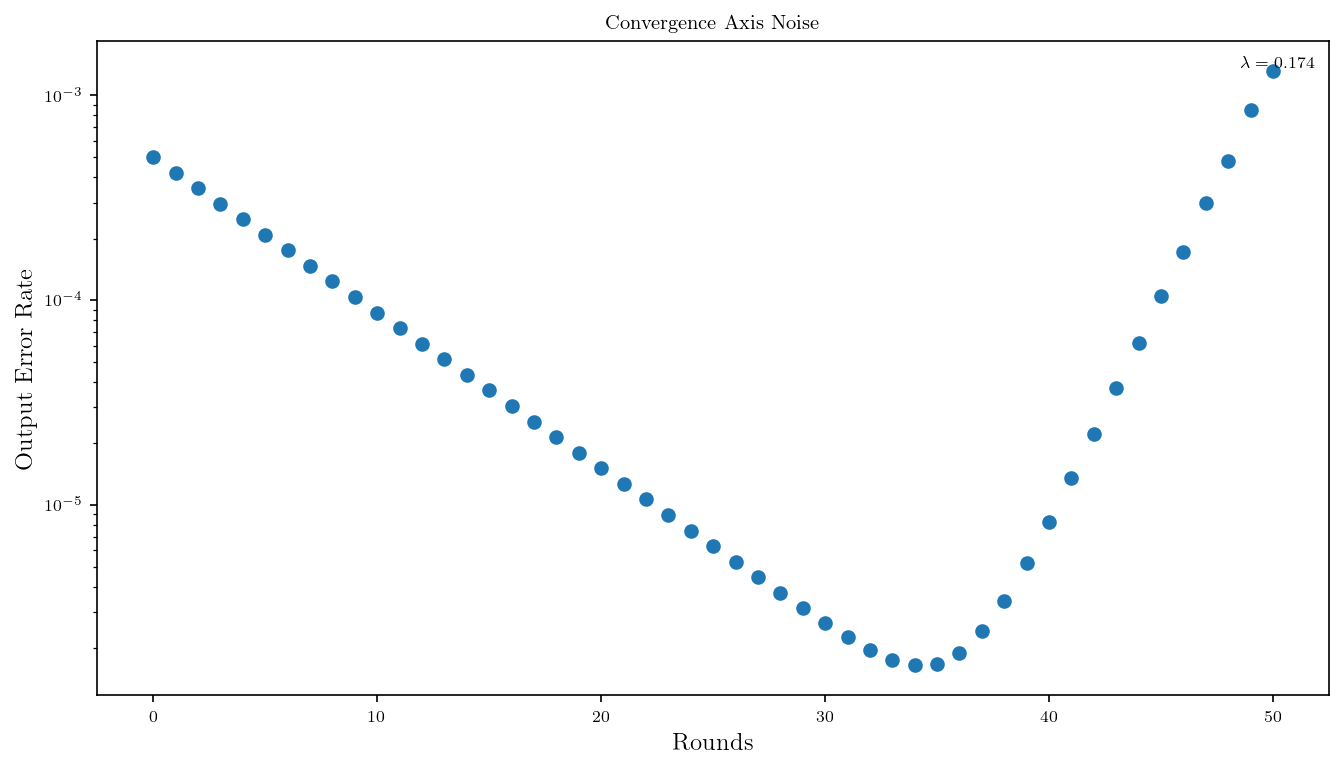

In [36]:
rounds_arr = np.array([r for r in range(rounds+1)])
output_error_rate = np.asarray(inf_to_error(infidelity_list, 1))

# Fit only the left, decreasing branch
# From your plot this looks roughly like rounds 0 to 16
fit_start = 0
fit_end = 33 # inclusive

mask = (rounds_arr >= fit_start) & (rounds_arr <= fit_end)

x_fit = rounds_arr[mask]
y_fit = output_error_rate[mask]

# Fit log(y) = a r + b
a, b = np.polyfit(x_fit, np.log(y_fit), 1)

lambda_ = -a          # exponential decay parameter
A = np.exp(b)       # prefactor
decay_factor = np.exp(a)  # multiplicative factor per round

print(f"A = {A:.6e}")
print(f"lambda = {lambda_:.6e}")
print(f"per-round decay factor = {decay_factor:.6e}")

# Fitted curve over the fitting region
y_fit_curve = A * np.exp(-lambda_ * x_fit)

plt.figure(figsize=(9, 5))

plt.plot(rounds_arr, output_error_rate, 'o', label='Output')
plt.xlabel("Rounds", fontsize=12)
plt.ylabel("Output Error Rate", fontsize=12)
plt.yscale('log')
plt.tight_layout()
# Legend with text only
dummy = plt.Line2D([], [], linestyle='none', label=rf'$\lambda={lambda_:.3g}$')
plt.legend(
    handles=[dummy],
    frameon=False,
    loc='upper right',
    handlelength=0,
    handletextpad=0
)
plt.title("Convergence Axis Noise")
plt.show()

Multiple input error rates on the same plot

In [48]:
rounds = 65
shots = 50

input_error_prob_list = np.array([5e-4, 1e-4, 5e-5, 1e-5, 5e-6, 1e-6])

rounds_arr = np.arange(rounds + 1)

# The backend can be constructed once.
backend = AerSimulator(method="density_matrix")


def run_distillation(input_error_prob):
    """Return the output-error-rate curve for one initial error probability."""

    infidelity_list = []

    # Initial noisy single-qubit density matrix.
    prep = (
        ry_theta
        @ np.array([[1], [0]])
        @ np.array([[1, 0]])
        @ ry_theta.conj().T
    )

    rho_in = (
        kraus0(input_error_prob)
        @ prep
        @ kraus0(input_error_prob).conj().T
        +
        kraus1(input_error_prob)
        @ prep
        @ kraus1(input_error_prob).conj().T
        +
        kraus2(input_error_prob)
        @ prep
        @ kraus2(input_error_prob).conj().T
    )

    rho_in = DensityMatrix(rho_in / np.trace(rho_in))

    initial_infidelity = 1 - state_fidelity(
        ideal_1q_dm,
        rho_in,
    )
    infidelity_list.append(initial_infidelity)

    for _ in range(rounds):
        rho_two = DensityMatrix(
            np.kron(rho_in.data, rho_in.data)
        )

        meas_circuit = QuantumCircuit(2, 1)
        meas_circuit.append(
            SetDensityMatrix(rho_two),
            meas_circuit.qubits,
        )

        # Two-qubit distillation decoder.
        meas_circuit.cx(0, 1)
        meas_circuit.h(0)

        # Measure qubit 1 and postselect on outcome 0.
        meas_circuit.measure(1, 0)

        meas_circuit.append(
            SaveDensityMatrix(
                num_qubits=2,
                label="dm_post",
                conditional=True,
                pershot=True,
            ),
            meas_circuit.qubits,
        )

        result = backend.run(
            meas_circuit,
            shots=shots,
        ).result()

        conditional_states = result.data()["dm_post"]

        if "0x0" not in conditional_states:
            raise RuntimeError(
                "No postselected 0 outcome was sampled. "
                "Increase the number of shots."
            )

        # All accepted shots have the same conditional density matrix
        # for this ideal decoder, so taking the first one is sufficient.
        rho_post_2q = conditional_states["0x0"][0]

        output_infidelity = 1 - state_fidelity(
            rho_post_2q,
            ideal_dm,
        )
        infidelity_list.append(output_infidelity)

        # Retain qubit 0 as the input to the next round.
        rho_in = partial_trace(rho_post_2q, [1])

    return np.asarray(inf_to_error(infidelity_list, 1))


# Simulate all initial error probabilities.
output_curves = {}

for input_error_prob in input_error_prob_list:
    output_curves[input_error_prob] = run_distillation(
        input_error_prob
    )

   5.000e-04     0.173878 
   1.000e-04     0.175172 
   5.000e-05     0.175191 
   1.000e-05     0.175202 
   5.000e-06     0.175203 
   1.000e-06     0.175205 


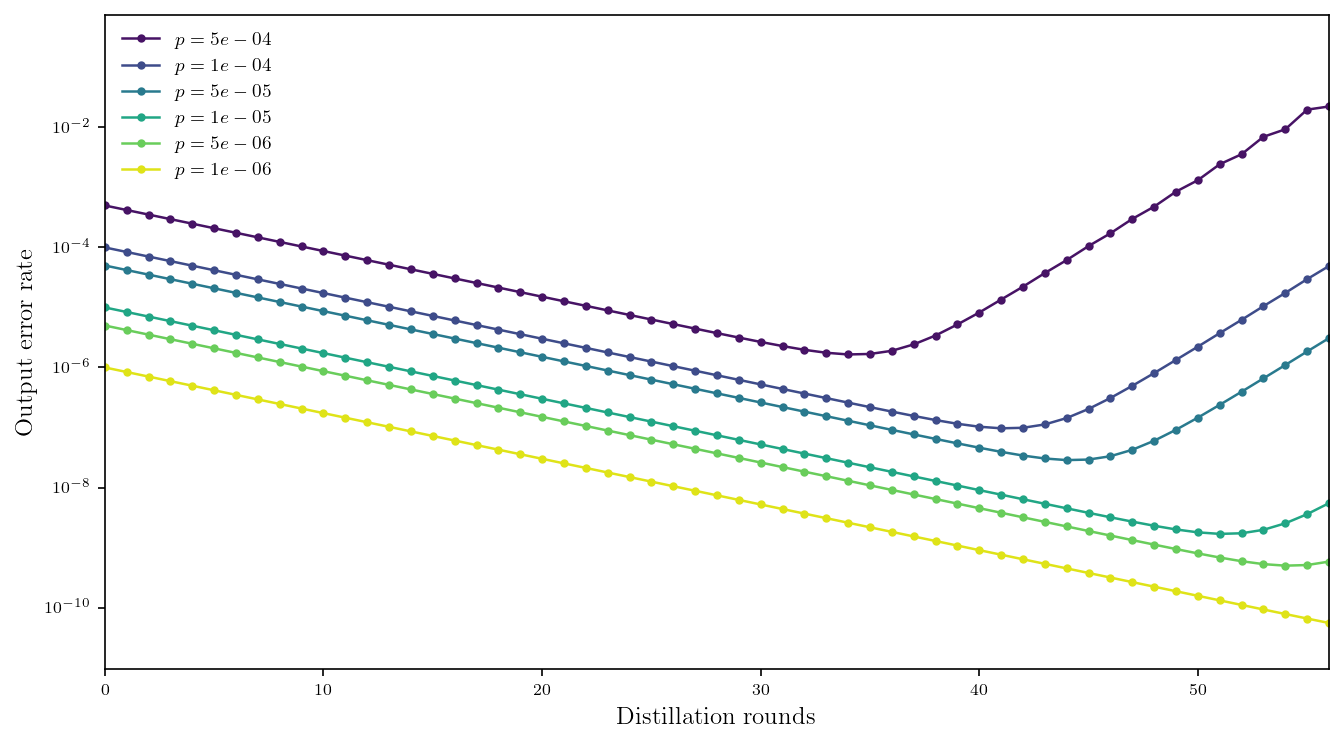

In [49]:
fit_start = 0
fit_end = 33

colors = plt.cm.viridis(
    np.linspace(0.05, 0.95, len(input_error_prob_list))
)

plt.figure(figsize=(9, 5))

for color, input_error_prob in zip(
    colors,
    input_error_prob_list,
):
    output_error_rate = output_curves[input_error_prob]

    # Fit only finite, strictly positive values.
    fit_mask = (
        (rounds_arr >= fit_start)
        & (rounds_arr <= fit_end)
        & np.isfinite(output_error_rate)
        & (output_error_rate > 0)
    )

    x_fit = rounds_arr[fit_mask]
    y_fit = output_error_rate[fit_mask]

    if len(x_fit) >= 2:
        slope, intercept = np.polyfit(
            x_fit,
            np.log(y_fit),
            1,
        )
        lambda_ = -slope
        print(
            f"{input_error_prob:12.3e} "
            f"{lambda_:12.6f} "
        )

    plt.plot(
        rounds_arr,
        output_error_rate,
        marker="o",
        markersize=3,
        linewidth=1.2,
        color=color,
        label=rf"$p={input_error_prob:.0e}$",
    )

plt.xlabel("Distillation rounds", fontsize=12)
plt.xlim(0,56)
plt.ylabel("Output error rate", fontsize=12)
plt.yscale("log")
plt.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

# Saving Data

In [50]:
# lambda_value is a hard-coded constant, not the fit result.
# Combine all output error-rate curves into a 2D array.
output_error_rate_matrix = np.stack([
    output_curves[p]
    for p in input_error_prob_list
])

# Save all simulation, theoretical, and fitting data.
np.savez_compressed(
    "../../../../data/two_qubit/physical_level/multiple_rounds/stable_axis_error_rates.npz",

    # Axes and input parameters.
    rounds_arr=rounds_arr,
    input_error_prob_list=input_error_prob_list,
    
    output_error_rate_matrix=output_error_rate_matrix, 

    # Exponential-fit information.
    fit_start=fit_start,
    fit_end=fit_end,
    lambda_value=0.1752,
)